# Proximity-Based Imputation & Outlier Detection

This notebook demonstrates two capabilities built on top of RF-GAP sparse proximities:

1. **Imputation** – filling missing values using proximity-weighted averages (continuous) or weighted votes (categorical), following Breiman's iterative approach.
2. **Outlier detection** – identifying class-relative outliers via squared-proximity sums and MAD-standardisation.

Both methods accept **numpy arrays** and **pandas DataFrames**.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
try:
    from aeon.classification.sklearn import RotationForestClassifier
except ImportError:
    from aeon.classification import RotationForestClassifier


from sktree import ObliqueRandomForestClassifier
from sklearn.metrics import r2_score, accuracy_score
from sklearn.model_selection import train_test_split

from forestgap import with_sparse_proximity

c:\Users\rhodes8\AppData\Local\miniconda3\envs\generalprox\Lib\site-packages\aeon\base\__init__.py:24: FutureWarning: The aeon package will soon be releasing v1.0.0 with the removal of legacy modules and interfaces such as BaseTransformer and BaseForecaster. This will contain breaking changes. See aeon-toolkit.org for more information. Set aeon.AEON_DEPRECATION_WARNING or the AEON_DEPRECATION_WARNING environmental variable to 'False' to disable this warning.
  warnings.warn(


## 1  Load the Iris dataset

In [2]:
df = pd.read_csv("../datasets/iris.csv")
print(f"Shape: {df.shape}")
df.head()

Shape: (150, 5)


,species,sepal_length,sepal_width,petal_length,petal_width
0,setosa,5.1,3.5,1.4,0.2
1,setosa,4.9,3.0,1.4,0.2
2,setosa,4.7,3.2,1.3,0.2
3,setosa,4.6,3.1,1.5,0.2
4,setosa,5.0,3.6,1.4,0.2


In [3]:
feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X = df[feature_cols]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (120, 4), Test: (30, 4)


---
## 2  Proximity-based imputation

### 2.1  Inject missing values

We randomly remove ~20 % of feature values to simulate missingness.

In [4]:
rng = np.random.RandomState(0)
miss_rate = 0.20

mask_train = rng.rand(*X_train.shape) < miss_rate
mask_test  = rng.rand(*X_test.shape)  < miss_rate

X_train_miss = X_train.copy()
X_test_miss  = X_test.copy()
X_train_miss[mask_train] = np.nan
X_test_miss[mask_test]   = np.nan

print(f"Missing training entries: {mask_train.sum()} / {mask_train.size}")
print(f"Missing test entries:     {mask_test.sum()} / {mask_test.size}")
X_train_miss.head(10)

Missing training entries: 96 / 480
Missing test entries:     23 / 120


,sepal_length,sepal_width,petal_length,petal_width
8,4.4,2.9,1.4,0.2
106,4.9,2.5,4.5,1.7
76,6.8,2.8,4.8,1.4
9,4.9,3.1,NaN,NaN
89,NaN,2.5,4.0,1.3
146,6.3,2.5,5.0,1.9
94,NaN,2.7,NaN,1.3
133,6.3,2.8,5.1,1.5
135,7.7,3.0,NaN,2.3
117,7.7,3.8,6.7,2.2


### 2.2  Rough initialisation & model fitting

The iterative algorithm starts by filling NaN with column medians, fits a forest, then uses proximity-weighted fills to refine.

In [5]:
# Rough fill with median
X_train_init = X_train_miss.fillna(X_train_miss.median())
X_test_init  = X_test_miss.fillna(X_train_miss.median())  # use train medians

ProxRF = with_sparse_proximity(ObliqueRandomForestClassifier)

n_iters = 50
imputed_train = X_train_init.copy()
imputed_test  = X_test_init.copy()

r2_per_iter = []

for i in range(n_iters):
    model = ProxRF(
        n_estimators=100, random_state=42,
        prox_method="rfgap",
    )
    model.fit(imputed_train.values, y_train.values)

    # Proximity-weighted imputation (DataFrame in → DataFrame out)
    imputed_train, imputed_test = model.impute(
        X_train_miss, X_test=X_test_miss, initialization = 'knn'
    )

    # Measure quality: R² of imputed vs. true values at missing positions
    train_true = X_train.values[mask_train]
    train_imp  = imputed_train.values[mask_train]
    r2 = r2_score(train_true, train_imp)
    r2_per_iter.append(r2)
    print(f"Iter {i+1}: R² (imputed vs. true at missing spots) = {r2:.4f}")

Iter 1: R² (imputed vs. true at missing spots) = 0.9182
Iter 2: R² (imputed vs. true at missing spots) = 0.9512
Iter 3: R² (imputed vs. true at missing spots) = 0.9657
Iter 4: R² (imputed vs. true at missing spots) = 0.9707
Iter 5: R² (imputed vs. true at missing spots) = 0.9700
Iter 6: R² (imputed vs. true at missing spots) = 0.9673
Iter 7: R² (imputed vs. true at missing spots) = 0.9671
Iter 8: R² (imputed vs. true at missing spots) = 0.9673
Iter 9: R² (imputed vs. true at missing spots) = 0.9672
Iter 10: R² (imputed vs. true at missing spots) = 0.9674
Iter 11: R² (imputed vs. true at missing spots) = 0.9680
Iter 12: R² (imputed vs. true at missing spots) = 0.9680
Iter 13: R² (imputed vs. true at missing spots) = 0.9678
Iter 14: R² (imputed vs. true at missing spots) = 0.9680
Iter 15: R² (imputed vs. true at missing spots) = 0.9680
Iter 16: R² (imputed vs. true at missing spots) = 0.9682
Iter 17: R² (imputed vs. true at missing spots) = 0.9682
Iter 18: R² (imputed vs. true at missing

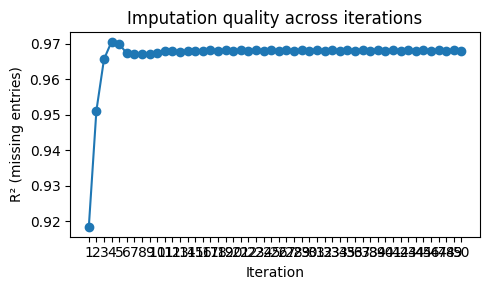

In [6]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(range(1, n_iters + 1), r2_per_iter, "o-")
ax.set_xlabel("Iteration")
ax.set_ylabel("R² (missing entries)")
ax.set_title("Imputation quality across iterations")
ax.set_xticks(range(1, n_iters + 1))
plt.tight_layout()
plt.show()

### 2.3  Imputed vs. true scatter plot

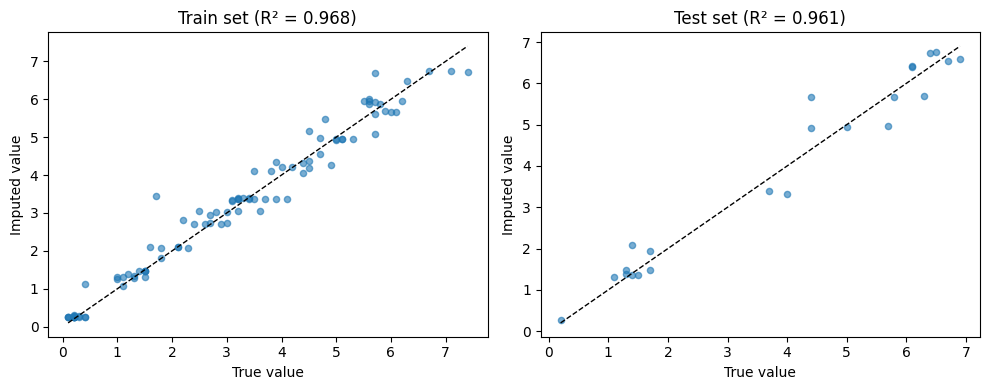

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (label, mask_arr, true_df, imp_df) in zip(
    axes,
    [
        ("Train", mask_train, X_train, imputed_train),
        ("Test",  mask_test,  X_test,  imputed_test),
    ],
):
    true_vals = true_df.values[mask_arr]
    imp_vals  = imp_df.values[mask_arr]
    r2 = r2_score(true_vals, imp_vals)

    ax.scatter(true_vals, imp_vals, alpha=0.6, s=20)
    lims = [min(true_vals.min(), imp_vals.min()), max(true_vals.max(), imp_vals.max())]
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_xlabel("True value")
    ax.set_ylabel("Imputed value")
    ax.set_title(f"{label} set (R² = {r2:.3f})")

plt.tight_layout()
plt.show()

### 2.4  DataFrame preservation

Verify that passing a DataFrame returns a DataFrame with the same index and columns.

In [8]:
print(f"Input type:  {type(X_train_miss).__name__}")
print(f"Output type: {type(imputed_train).__name__}")
print(f"Columns preserved: {list(imputed_train.columns)}")
print(f"Index matches: {(imputed_train.index == X_train_miss.index).all()}")
print(f"Any NaN remaining (train): {imputed_train.isna().any().any()}")
print(f"Any NaN remaining (test):  {imputed_test.isna().any().any()}")

Input type:  DataFrame
Output type: DataFrame
Columns preserved: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
Index matches: True
Any NaN remaining (train): False
Any NaN remaining (test):  False


### 2.5  Numpy array path

The same method works when raw numpy arrays are passed.

In [9]:
imp_arr = model.impute(X_train_miss.values)
print(f"Type: {type(imp_arr).__name__}, shape: {imp_arr.shape}")
print(f"Any NaN: {np.isnan(imp_arr).any()}")

Type: ndarray, shape: (120, 4)
Any NaN: False


---
## 3  Outlier detection

We fit a model on the clean data, then compute Breiman's proximity-based outlier scores.

### 3.1  Baseline – clean data

In [10]:
model_clean = ProxRF(
    n_estimators=200, random_state=42,
    prox_method="rfgap",
)
model_clean.fit(X_train.values, y_train.values)

# Pass a pandas Series → returns a pandas Series
scores_clean = model_clean.outlier_scores(y_train)
print(f"Return type: {type(scores_clean).__name__}")
print(f"Index preserved: {(scores_clean.index == y_train.index).all()}")
print(scores_clean.describe())

Return type: Series
Index preserved: True
count    120.000000
mean      10.307640
std       37.730646
min        0.003641
25%        0.431872
50%        1.000000
75%        2.921110
max      329.192879
Name: outlier_score, dtype: float64


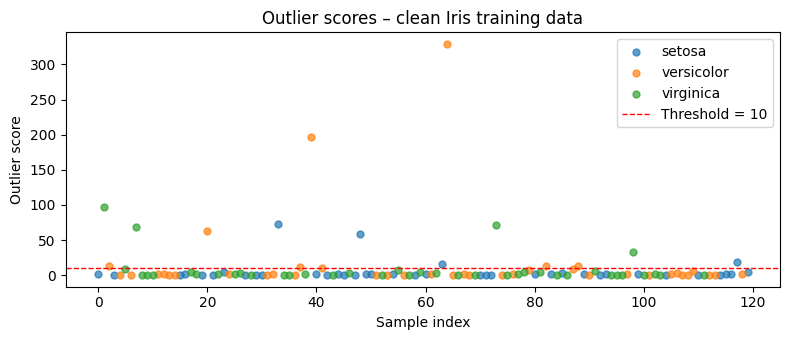

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.5))
classes = y_train.unique()
for cls in sorted(classes):
    idx = y_train == cls
    ax.scatter(
        np.where(idx)[0], scores_clean[idx],
        label=cls, alpha=0.7, s=25,
    )
ax.axhline(10, color="red", ls="--", lw=1, label="Threshold = 10")
ax.set_xlabel("Sample index")
ax.set_ylabel("Outlier score")
ax.set_title("Outlier scores – clean Iris training data")
ax.legend()
plt.tight_layout()
plt.show()

### 3.2  Inject artificial outliers

We corrupt a few training samples with large noise to see if the outlier scores pick them up.

In [12]:
n_outliers = 5
rng2 = np.random.RandomState(99)
outlier_idx = rng2.choice(X_train.shape[0], size=n_outliers, replace=False)

X_train_corrupt = X_train.values.copy()
X_train_corrupt[outlier_idx] += rng2.normal(0, 15, size=(n_outliers, X_train.shape[1]))

model_corrupt = ProxRF(
    n_estimators=200, random_state=42,
    prox_method="rfgap",
)
model_corrupt.fit(X_train_corrupt, y_train.values)

# Use numpy y → returns numpy array
scores_corrupt = model_corrupt.outlier_scores(y_train.values)
print(f"Return type: {type(scores_corrupt).__name__}")
print(f"Corrupted sample scores: {scores_corrupt[outlier_idx]}")

Return type: ndarray
Corrupted sample scores: [1244.86917481  129.88612467  519.85139997  117.53165767  342.34979784]


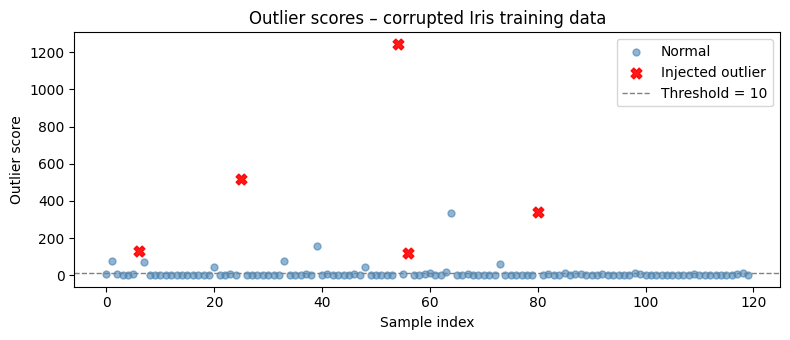

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.5))
is_outlier = np.zeros(X_train.shape[0], dtype=bool)
is_outlier[outlier_idx] = True

ax.scatter(
    np.where(~is_outlier)[0], scores_corrupt[~is_outlier],
    label="Normal", alpha=0.6, s=25, color="steelblue",
)
ax.scatter(
    np.where(is_outlier)[0], scores_corrupt[is_outlier],
    label="Injected outlier", alpha=0.9, s=60, color="red", marker="X",
)
ax.axhline(10, color="grey", ls="--", lw=1, label="Threshold = 10")
ax.set_xlabel("Sample index")
ax.set_ylabel("Outlier score")
ax.set_title("Outlier scores – corrupted Iris training data")
ax.legend()
plt.tight_layout()
plt.show()

### 3.3  Scaling options

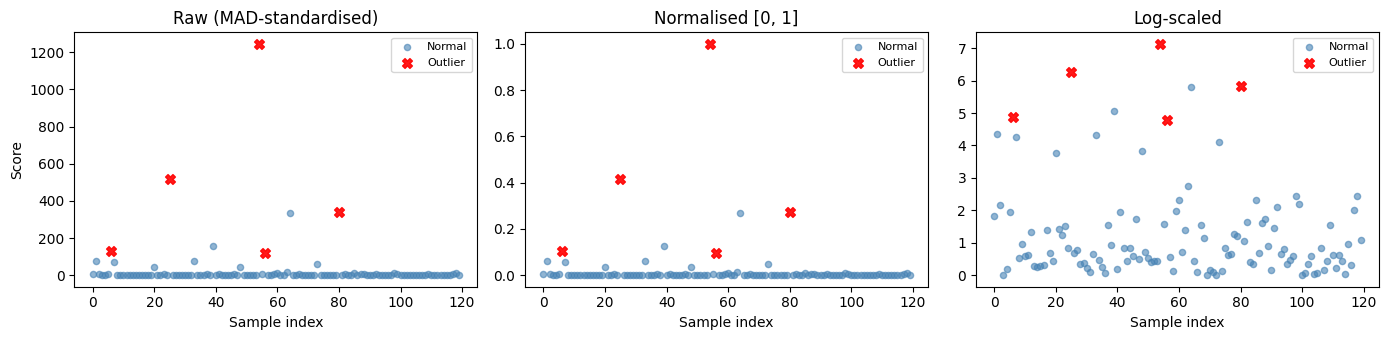

In [14]:
scores_norm = model_corrupt.outlier_scores(y_train.values, scaling="normalize")
scores_log  = model_corrupt.outlier_scores(y_train.values, scaling="log")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=False)

titles = ["Raw (MAD-standardised)", "Normalised [0, 1]", "Log-scaled"]
for ax, s, title in zip(axes, [scores_corrupt, scores_norm, scores_log], titles):
    ax.scatter(
        np.where(~is_outlier)[0], s[~is_outlier],
        alpha=0.6, s=20, color="steelblue", label="Normal",
    )
    ax.scatter(
        np.where(is_outlier)[0], s[is_outlier],
        alpha=0.9, s=50, color="red", marker="X", label="Outlier",
    )
    ax.set_title(title)
    ax.set_xlabel("Sample index")
    ax.legend(fontsize=8)

axes[0].set_ylabel("Score")
plt.tight_layout()
plt.show()

### 3.4  Feature-space scatterplot coloured by outlier score

Each training point is plotted in the first two feature dimensions, with size and colour proportional to the normalised outlier score.

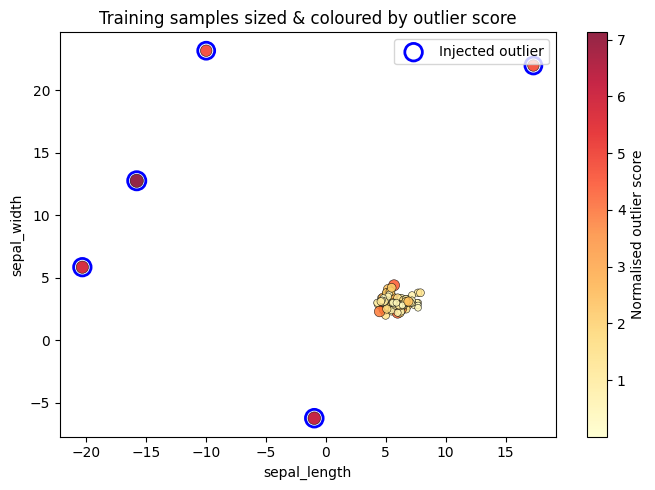

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))

sizes = 20 + 10 * scores_log  # scale marker area
sc = ax.scatter(
    X_train_corrupt[:, 0], X_train_corrupt[:, 1],
    c=scores_log, s=sizes, cmap="YlOrRd", edgecolors="k", linewidths=0.4, alpha=0.85,
)
# Mark injected outliers with an extra ring
ax.scatter(
    X_train_corrupt[outlier_idx, 0], X_train_corrupt[outlier_idx, 1],
    facecolors="none", edgecolors="blue", linewidths=2, s=sizes[outlier_idx] + 80,
    label="Injected outlier",
)
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Normalised outlier score")
ax.set_xlabel(feature_cols[0])
ax.set_ylabel(feature_cols[1])
ax.set_title("Training samples sized & coloured by outlier score")
ax.legend()
plt.tight_layout()
plt.show()

### 3.5  Summary table of top outliers

In [16]:
top_k = 10
order = np.argsort(scores_corrupt)[::-1][:top_k]

summary = pd.DataFrame({
    "sample_idx": order,
    "class": y_train.values[order],
    "outlier_score": scores_corrupt[order],
    "injected": is_outlier[order],
})
summary

,sample_idx,class,outlier_score,injected
0,54,setosa,1244.869175,True
1,25,virginica,519.851400,True
2,80,setosa,342.349798,True
3,64,versicolor,333.159421,False
4,39,versicolor,157.939479,False
5,6,versicolor,129.886125,True
6,56,versicolor,117.531658,True
7,1,virginica,77.580063,False
8,33,setosa,74.975544,False
9,7,virginica,69.211943,False
